# 22 - Netflix Content Strategy Analysis: what the viewing-hours data can and cannot say
**Topic:** Data Visualization  |  **Reference:** "Netflix Content Strategy Analysis with Python" (amanxai.com, Sep 2024)

**Question.** What kind of content gets watched on Netflix, and does *when* a title is released matter?

**Reference method:** load a table of 24,812 titles with viewing hours, group by content type, language and release month/season, draw bar and pie charts, and read strategy lessons off them.
**What I check before drawing conclusions:** (1) the **data quality** (67% of titles have no release date; some titles appear twice; hours are written in the Indian digit-grouping style); (2) how **concentrated** viewing is (a few titles take a large share, so averages mislead); (3) release timing **with the age confound removed** (a title released in January has had more time to be watched than one released in November); (4) language and availability comparisons with intervals.

## 1. Libraries and data

In [1]:
import warnings, os, re, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mt, seaborn as sns
import statsmodels.formula.api as smf
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
raw = pd.read_csv("../_data/netflix_content.csv")
print(raw.shape); print(raw.dtypes.astype(str).to_dict()); raw.head(4)

(24812, 6)
{'Title': 'str', 'Available Globally?': 'str', 'Release Date': 'str', 'Hours Viewed': 'str', 'Language Indicator': 'str', 'Content Type': 'str'}


,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type
0,The Night Agent: Season 1,Yes,2023-03-23,"81,21,00,000",English,Show
1,Ginny & Georgia: Season 2,Yes,2023-01-05,"66,51,00,000",English,Show
2,The Glory: Season 1 // 더 글로리: 시즌 1,Yes,2022-12-30,"62,28,00,000",Korean,Show
3,Wednesday: Season 1,Yes,2022-11-23,"50,77,00,000",English,Show


**Hours are text** in the Indian digit-grouping style (`81,21,00,000` means 812,100,000 hours). Removing the commas gives the right number; I check that by comparing the largest values with the first rows.

In [2]:
df = raw.copy()
df["hours"] = df["Hours Viewed"].str.replace(",", "").astype(float); df["release"] = pd.to_datetime(df["Release Date"], errors="coerce")
df = df.rename(columns={"Available Globally?": "global", "Language Indicator": "language", "Content Type": "type"})
print("top hours (millions):", (df.hours.nlargest(3) / 1e6).round(0).tolist(), "| smallest:", df.hours.min())
print("missing release date: %d of %d (%.0f%%)" % (df.release.isna().sum(), len(df), df.release.isna().mean() * 100))
print("release dates from %s to %s" % (df.release.min().date(), df.release.max().date()))
d = df[df.Title.duplicated(keep=False)].sort_values("Title"); print("rows whose title appears more than once: %d (%d distinct titles)" % (len(d), d.Title.nunique())); print(d.head(6)[["Title", "global", "release", "hours", "language", "type"]].to_string(index=False))

top hours (millions): [812.0, 665.0, 630.0] | smallest: 100000.0
missing release date: 16646 of 24812 (67%)
release dates from 2010-04-01 to 2023-12-31
rows whose title appears more than once: 11308 (5654 distinct titles)
                                      Title global    release      hours language type
#NoFilter: Season 1 // Sem Filtro: Season 1    Yes 2023-02-15 24200000.0  English Show
#NoFilter: Season 1 // Sem Filtro: Season 1    Yes 2023-02-15  3600000.0  English Show
                         #blackAF: Season 1    Yes 2020-04-17  1600000.0  English Show
                         #blackAF: Season 1    Yes 2020-04-17   900000.0  English Show
                         (Un)Well: Season 1    Yes 2020-08-12  2500000.0  English Show
                         (Un)Well: Season 1    Yes 2020-08-12  2300000.0  English Show


## 2. Data quality: who has a release date, and what are the repeated titles?

In [3]:
df["has_date"] = df.release.notna()
print(df.groupby("type").has_date.mean().mul(100).round(0).to_dict(), "% with a release date, by type")
print(df.groupby("global").has_date.mean().mul(100).round(0).to_dict(), "% with a release date, by global availability")
print(df.groupby("has_date").hours.agg(["size", "median", "mean"]).round(0).to_string())
rep = df.groupby("Title").agg(n=("hours", "size"), same_type=("type", "nunique"), glob=("global", lambda s: "|".join(sorted(set(s)))), h_min=("hours", "min"), h_max=("hours", "max")); rep = rep[rep.n > 1]
print("\nrepeated titles: %d | how many rows each: %s | differing 'global' flags: %d" % (len(rep), rep.n.value_counts().to_dict(), (rep.glob.str.contains("\\|")).sum()))
print("share of repeated titles with identical hours in all copies: %.0f%%" % ((rep.h_min == rep.h_max).mean() * 100))

{'Movie': 25.0, 'Show': 44.0} % with a release date, by type
{'No': 8.0, 'Yes': 89.0} % with a release date, by global availability


           size     median        mean
has_date                              
False     16646   600000.0   4059468.0
True       8166  3000000.0  11122704.0



repeated titles: 5654 | how many rows each: {2: 5654} | differing 'global' flags: 114
share of repeated titles with identical hours in all copies: 8%


**Reading it.**
* **Two thirds of the rows (16,646 of 24,812) have no release date**, and the missing ones are *not random*: 92% of the titles that are not available globally have no date (89% of global titles have one), and 75% of movies lack a date against 56% of shows. Titles without a date are also much less watched (median 0.6 M hours vs 3.0 M for dated titles). Any chart by release date therefore describes a **small, more successful, mostly global slice** of the catalogue, not the whole catalogue.
* **Every repeated title appears exactly twice** (5,654 titles, 11,308 rows) and in 92% of the pairs the two rows have *different* hours (for example #NoFilter: Season 1 with 24.2 M and 3.6 M hours). The file has no period column, but this pattern is what one would expect if two reporting periods were stacked; the data source is not documented here, so I treat the two rows as separate observations and avoid statements that assume one row = one title for the whole year. 114 pairs even disagree on the "global" flag, so the flag can change between the copies.
* The hours were written in the Indian digit-grouping style as text ("81,21,00,000"); stripping the commas gives 812.1 million hours for the most-watched row, matching the first rows of the file.

I keep every row for the viewing-hours analysis but treat the **release-date** analysis (section 5) as a *subsample* (titles with a date) and say so on every chart that uses it.

## 3. How concentrated is viewing?

share of all hours: top 1% of rows 24% | top 10% 68% | top 50% 97% | Gini coefficient 0.80
median 1.1 M hours | mean 6.4 M | titles above the mean: 20%


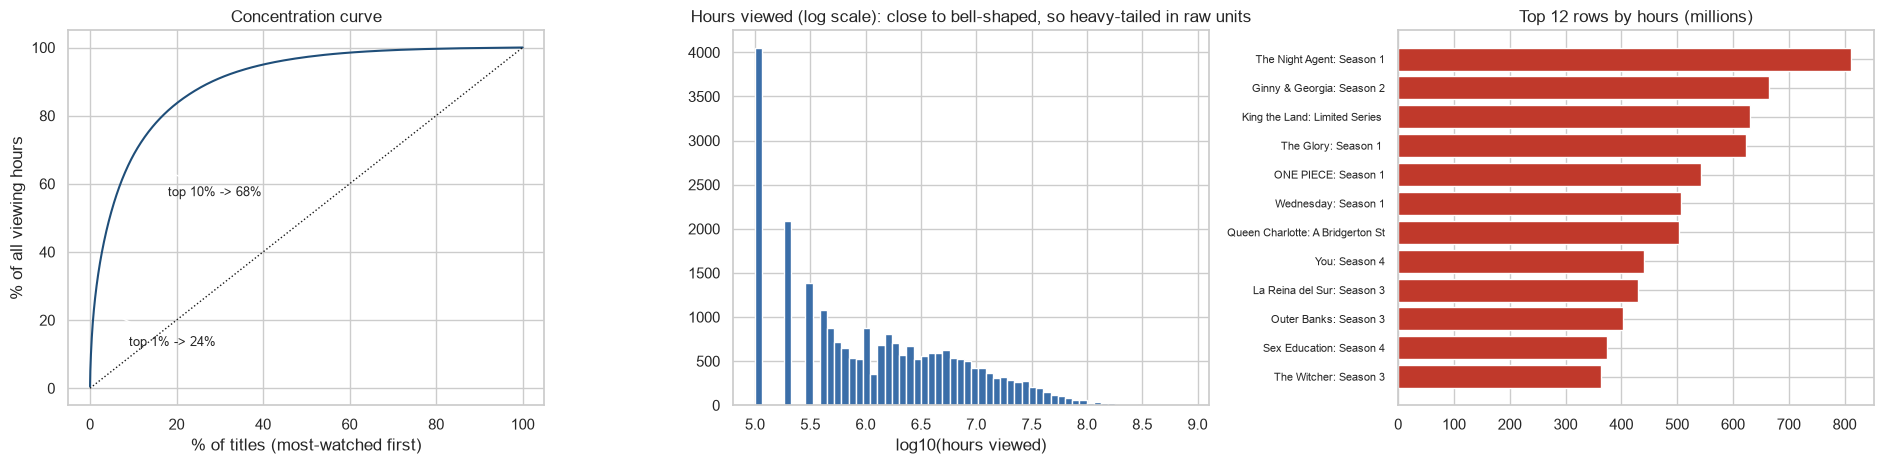

In [4]:
h = df.hours.sort_values(ascending=False).reset_index(drop=True); cum = h.cumsum() / h.sum(); n = len(h)
gini = 1 - 2 * ((h.sort_values().cumsum() / h.sum()).sum() - 0.5) / n
print("share of all hours: top 1%% of rows %.0f%% | top 10%% %.0f%% | top 50%% %.0f%% | Gini coefficient %.2f" % (cum.iloc[int(.01 * n) - 1] * 100, cum.iloc[int(.1 * n) - 1] * 100, cum.iloc[int(.5 * n) - 1] * 100, gini))
print("median %.1f M hours | mean %.1f M | titles above the mean: %.0f%%" % (h.median() / 1e6, h.mean() / 1e6, (h > h.mean()).mean() * 100))
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].plot(np.arange(1, n + 1) / n * 100, cum * 100, color="#1f4e79"); ax[0].plot([0, 100], [0, 100], "k:", lw=1); ax[0].set_xlabel("% of titles (most-watched first)"); ax[0].set_ylabel("% of all viewing hours"); ax[0].set_title("Concentration curve")
for p_, y_ in [(1, cum.iloc[int(.01 * n) - 1]), (10, cum.iloc[int(.1 * n) - 1])]: ax[0].annotate(f"top {p_}% -> {y_*100:.0f}%", (p_, y_ * 100), xytext=(p_ + 8, y_ * 100 - 12), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax[1].hist(np.log10(df.hours), bins=60, color="#3b6ea8"); ax[1].set_xlabel("log10(hours viewed)"); ax[1].set_title("Hours viewed (log scale): close to bell-shaped, so heavy-tailed in raw units")
top = df.nlargest(12, "hours"); ax[2].barh(top.Title.str.split("//").str[0].str.slice(0, 32)[::-1], (top.hours / 1e6)[::-1], color="#c0392b"); ax[2].set_title("Top 12 rows by hours (millions)"); ax[2].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

**Reading it.** Viewing is extremely concentrated: **the top 1% of rows account for 24% of all hours, the top 10% for 68%, and the top half for 97%** (Gini coefficient 0.80). The median is 1.1 M hours but the mean is 6.4 M and only **20% of rows are above the mean**: averages are dominated by a few hits, which is why I use medians below. On a log scale the distribution is roughly bell-shaped, so a few multiplicative differences (a hit is 100x a typical title) drive everything. The right-hand panel lists the twelve most-watched rows.

## 4. Type, language and availability (medians with bootstrap intervals)
Because hours are so skewed, I report the **median** (and the mean for reference) with 95% bootstrap intervals; shows are counted per *title row* (a season or a film), not per episode, so "hours per title" of shows and movies mix different amounts of runtime.

      by       group  titles  median_M  ci_low  ci_high  mean_M  share_of_hours_%
    type       Movie   14104       0.5     0.5     0.50    3.59             31.97
    type        Show   10708       2.5     2.4     2.60   10.06             68.03
  global          No   17162       0.7     0.6     0.70    4.26             46.17
  global         Yes    7650       2.8     2.7     2.90   11.15             53.83
language     English   17268       1.4     1.3     1.40    7.21             78.56
language       Hindi     374       0.8     0.6     1.00    2.48              0.58
language    Japanese    2297       0.7     0.6     0.70    3.09              4.48
language      Korean    1582       1.7     1.4     2.05    9.72              9.71
language Non-English    3252       0.4     0.4     0.50    3.21              6.59
language     Russian      39       0.3     0.1     0.50    2.94              0.07


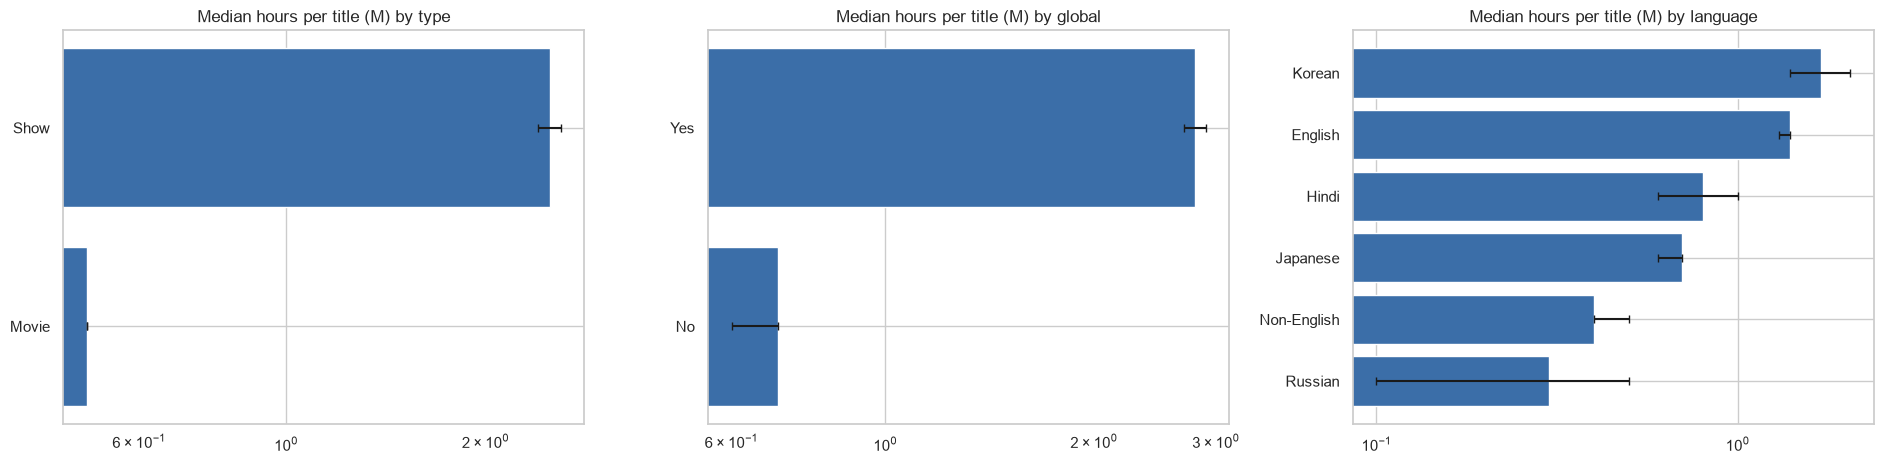

In [5]:
rng = np.random.RandomState(0)
def med_ci(x, B=1000): bs = [np.median(rng.choice(x, len(x))) for _ in range(B)]; return np.median(x), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
rows = []
for col in ["type", "global", "language"]:
    for g, s in df.groupby(col):
        m, lo, hi = med_ci(s.hours.to_numpy()); rows.append([col, g, len(s), m / 1e6, lo / 1e6, hi / 1e6, s.hours.mean() / 1e6, s.hours.sum() / df.hours.sum() * 100])
G = pd.DataFrame(rows, columns=["by", "group", "titles", "median_M", "ci_low", "ci_high", "mean_M", "share_of_hours_%"]); print(G.round(2).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for a, col in zip(ax, ["type", "global", "language"]):
    g = G[G.by == col].sort_values("median_M"); a.barh(g.group, g.median_M, xerr=[g.median_M - g.ci_low, g.ci_high - g.median_M], color="#3b6ea8", ecolor="k", capsize=3); a.set_title(f"Median hours per title (M) by {col}"); a.set_xscale("log")
plt.tight_layout(); plt.show()

**Reading it (median hours per row, bootstrap 95% interval).**
* **Shows vs movies:** median 2.5 M (2.4-2.6) vs 0.5 M (0.5-0.5). Shows account for 68% of all hours from 43% of the rows. A row for a show is a *season* with many episodes, a film is one sitting, so the gap in hours partly reflects runtime, not appeal.
* **Global availability:** titles available globally have a median of 2.8 M vs 0.7 M. This is very likely confounded (the biggest productions are released globally), so it does not show what a global release *would do* for a given title.
* **Language:** English-language titles are 70% of the rows and 79% of the hours; **Korean titles stand out (median 1.7 M, 6.4% of rows, 9.7% of hours)**, ahead of the English median 1.4 M; Japanese 0.7 M, Hindi 0.8 M, the catch-all "Non-English" 0.4 M. Intervals for the small groups (Russian: 39 rows, Hindi: 374) are wide, so I would not rank them.
* None of these comparisons adjusts for the age of a title or for the repeated rows.

## 5. Does the release month matter? Removing the age confound
In the reference, hours are compared across release months. But a title released in January 2023 has been available far longer than one released in December 2023, so more viewing is expected for the earlier release whatever the month. I use titles **released during 2023** (the year of the data, so every title has an exposure of at most 12 months), compute **days on the platform** at the end of the year, and then regress log hours on release month with and without the exposure control.

titles released in 2023 with a date: 786 (10% of all dated titles)
joint test that release month matters: WITHOUT exposure control F=2.4 p=0.006 | WITH exposure control (log days on platform) F=2.7 p=0.0019
coefficient of log(days on platform): 0.42 (95% CI -0.09 to 0.94); R-squared 0.04 -> 0.04


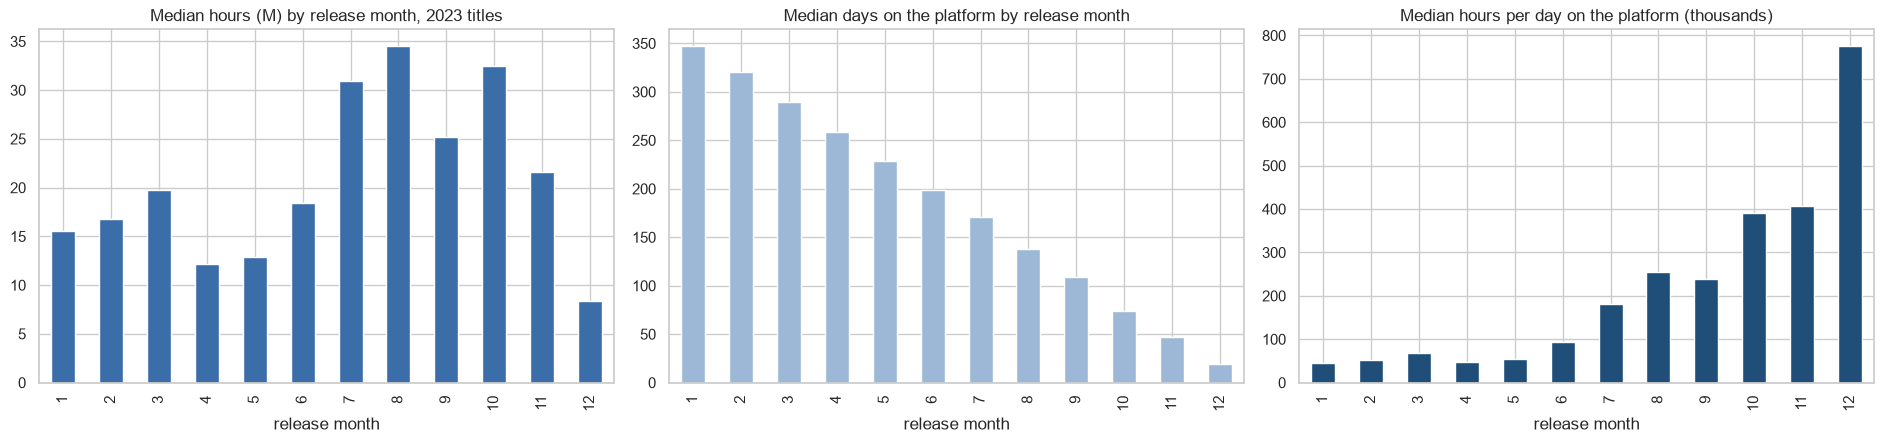

In [6]:
d23 = df[(df.release >= "2023-01-01") & (df.release <= "2023-12-31")].copy(); d23["month"] = d23.release.dt.month; d23["days_avail"] = (pd.Timestamp("2023-12-31") - d23.release).dt.days + 1; d23["log_h"] = np.log(d23.hours)
print("titles released in 2023 with a date:", len(d23), "(%.0f%% of all dated titles)" % (len(d23) / df.has_date.sum() * 100))
raw_m = d23.groupby("month").hours.median() / 1e6; per_day = (d23.hours / d23.days_avail).groupby(d23.month).median() / 1e3
m0 = smf.ols("log_h ~ C(month) + C(type)", d23).fit(cov_type="HC3"); m1 = smf.ols("log_h ~ C(month) + C(type) + np.log(days_avail)", d23).fit(cov_type="HC3")
f0 = m0.f_test(" , ".join(f"C(month)[T.{k}] = 0" for k in range(2, 13))); f1 = m1.f_test(" , ".join(f"C(month)[T.{k}] = 0" for k in range(2, 13)))
print("joint test that release month matters: WITHOUT exposure control F=%.1f p=%.2g | WITH exposure control (log days on platform) F=%.1f p=%.2g" % (float(f0.fvalue), float(f0.pvalue), float(f1.fvalue), float(f1.pvalue)))
print("coefficient of log(days on platform): %.2f (95%% CI %.2f to %.2f); R-squared %.2f -> %.2f" % (m1.params["np.log(days_avail)"], *m1.conf_int().loc["np.log(days_avail)"], m0.rsquared, m1.rsquared))
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
raw_m.plot.bar(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Median hours (M) by release month, 2023 titles"); ax[0].set_xlabel("release month")
d23.groupby("month").days_avail.median().plot.bar(ax=ax[1], color="#9db8d6"); ax[1].set_title("Median days on the platform by release month"); ax[1].set_xlabel("release month")
per_day.plot.bar(ax=ax[2], color="#1f4e79"); ax[2].set_title("Median hours per day on the platform (thousands)"); ax[2].set_xlabel("release month")
plt.tight_layout(); plt.show()

**Reading it (786 titles released in 2023 and with a date).**
* The first panel looks like a clear pattern: titles released in **July-October have the highest medians (31-35 M hours)** and December the lowest (8 M). The second panel shows that titles released early in the year had much longer to be watched (about 350 days for January vs 20 for December). Yet the January titles do *not* have the most hours: the data were evidently collected for a window that I cannot see, and viewing is front-loaded after release.
* The third panel divides by days on the platform: the figure shoots up for late-year titles (775 K hours per day for December) simply because a short exposure divides a similar amount of viewing by few days. **Neither the raw nor the per-day view is a fair comparison**, because the right control would be the number of days of the *reporting window* each title was available, which is not in the file.
* Statistically, the release month still matters jointly with or without a control for log days on the platform (F-test p = 0.006 without it, 0.002 with it), but R-squared is only 0.04: month explains about 4% of the variance in log hours, and the effect of days on the platform is imprecise (elasticity 0.42, 95% interval -0.09 to 0.94). So: **release timing is associated with hours, but the data cannot tell a "summer release strategy" from a reporting-window artefact.** The reference's seasonal "strategy" conclusions go beyond what this table supports.

## 6. Seasons of a show: do later seasons win?
Titles of the form "X: Season N" can be grouped by season number. Shows with many seasons survived because earlier seasons did well (survivorship), so a rising pattern would be partly selection.

In [7]:
sh = df[(df.type == "Show")].copy(); sh["season"] = sh.Title.str.extract(r"Season (\d+)", expand=False).astype(float); sh = sh.dropna(subset=["season"])
sh["season_bin"] = pd.cut(sh.season, [0, 1, 2, 3, 5, 100], labels=["1", "2", "3", "4-5", "6+"])
S = sh.groupby("season_bin", observed=True).hours.agg(["size", "median", "mean"]); S[["median", "mean"]] /= 1e6; print(S.round(2).to_string())
base = sh.assign(root=sh.Title.str.split(":").str[0]); rep = base.groupby("root").season.nunique(); print("shows with at least one season in the data: %d | with 2+ seasons listed: %d" % (len(rep), (rep > 1).sum()))

            size  median   mean
season_bin                     
1           5743     2.1   9.04
2           1935     2.6  10.02
3           1038     3.2  10.82
4-5         1029     4.1  13.60
6+           927     3.7  11.99
shows with at least one season in the data: 3593 | with 2+ seasons listed: 1137


**Reading it.** Median hours rise with the season number: 2.1 M for season 1, 2.6 M for season 2, 3.2 M for season 3, 4.1 M for seasons 4-5 and 3.7 M for 6+. That looks like "later seasons do better", but this is survivorship: a show reaches season 4 only if earlier seasons succeeded, so the later-season group is made of past winners (and a return of its audience). Only 1,137 of 3,593 shows have more than one season in the file, so the comparison is also incomplete.

## 7. Save the cleaned data and the analysis tables for the app

In [8]:
df[["Title", "global", "release", "hours", "language", "type"]].assign(hours_m=lambda x: x.hours / 1e6).drop(columns="hours").to_csv("model/netflix_clean.csv.gz", index=False, compression="gzip")
json.dump({"n_titles": int(len(df)), "missing_release_pct": float(df.release.isna().mean() * 100), "gini": float(gini), "top1_share": float(cum.iloc[int(.01 * n) - 1]), "top10_share": float(cum.iloc[int(.1 * n) - 1]), "groups": G.round(3).to_dict("records"),
           "month_test": {"F_without_exposure": float(f0.fvalue), "p_without": float(f0.pvalue), "F_with_exposure": float(f1.fvalue), "p_with": float(f1.pvalue), "elasticity_days": float(m1.params["np.log(days_avail)"])}}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['meta.json', 'netflix_clean.csv.gz']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data audit | none | 67% of rows have no release date (not at random), every repeated title is a pair with different hours (92%), hours stored as Indian-style text |
| Averages | mean hours by group | medians with bootstrap intervals (mean is 6x the median; top 10% of rows = 68% of hours) |
| Release timing | hours by month/season | restricted to 2023 releases, exposure examined: raw and per-day views both misleading; month explains about 4% of variance |
| Seasons | later seasons draw more | rise is real in the table but is survivorship |
| Conclusions | "strategy lessons" | what the table supports (concentration, shows vs movies, Korean titles) vs what it does not (timing strategy, effect of global release) |

**What I learned.** (1) Audit missing values: *which* rows are missing changes the meaning of a chart. (2) With a heavy-tailed target, report medians and concentration. (3) Time-since-release is a confounder in any "release month" chart. (4) A chart is evidence for a claim only if the comparison is fair; say what the data cannot answer.

**Limits.** No reporting period, no runtime, no genre, no budget, no marketing; two stacked rows per repeated title; 33% date coverage. **Next step:** get the reporting windows and runtimes (hours per runtime hour), then compare launches by days-in-window.